## Итоговый проект по дисциплине "Обучение с подкреплением". Чернова Ирина
## **Трек 2.Управление запасом одного товара с задержкой поставки**

**Задача**

Дискретное управление запасом одного товара на горизонте 30 дней. Каждый день
агент выбирает заказ *order ∈ {0..10}*; заказ приходит через *L* дней (*lead time*); спрос
случаен (*Poisson(5)*); при нехватке товара возникает Out of stock, при избытке товар отправляется на внешний склад. Награда за день = выручка минус закупка, хранение, штрафы за Out of stock и переполнение (хранение на внешнем складе).

**Исследовательский вопрос**

Насколько качество политики управления запасом падает при увеличении задержки
поставки *L*, и при каком *L* агент перестаёт справляться?

**Гипотеза**

Качество монотонно падает с ростом *L*; есть порог *L*, после которого
Out of stock резко растёт, а средняя награда падает заметно быстрее.

**Метрика**

На отложенной оценке (20 эпизодов, seed'ы 1000–1019) при каждом *L*:
- средняя награда за эпизод;
- средний Out of stock в день.

**План сравнения**

**Обучение (базовое условие):** PPO обучается при фиксированном *L_train = 1*,
  три seed (42, 123, 777), одинаковый бюджет 1_000_000 шагов.
  Наблюдение не нормализуется (*norm_obs=False*), награда нормализуется
  (*norm_reward=True*) для стабильности обучения.

**Оценка:** те же три обученные модели при *L ∈ {1, 3, 5, 7, 10}*, включая
  уровни, не виденные при обучении. Для каждой модели одни и те же 20 тестовых
  эпизодов (seed'ы 1000–1019), *random_init=False* (фиксированный старт *stock = 20*).  Для каждой модели усредняем награду по 20 эпизодам, затем по трём seed'ам; *std* разброс между seed'ами обучения.

**Ориентиры (бейзлайны):** оцениваются на тех же эпизодах и при тех же *L*.
  Результат PPO сравнивается с ними, чтобы понять, падает ли только RL
  или вся задача объективно усложняется.
  
Для всех условий задается одинаковое число тестовых эпизодов, одинаковые seed'ы, одинаковые коэффициенты награды.

**Бейзлайны (ориентиры)**

1. *random* случайная политика: действие выбирается равномерно из
   *{0..10}*. Нижняя граница: если агент не лучше random, он не выучил ничего
   полезного.
2. *order-up-to 25 (OUL25)* простая эвристика с фиксированным целевым
   уровнем запаса: каждый день заказываем столько, чтобы суммарный запас
   (*stock + sum(pipeline)*) стал равен 25. Не знает про *L* и не пересчитывается при изменении задержки.
3. *smart order-up-to (smart OUL)* эвристика с safety stock, которая
   знает текущий *L* и пересчитывает целевой уровень под него:
   *target = μ·(L+1) + z·sqrt(μ·(L+1))*, где *μ = 5*, *z = 1.65* (стандартная формула страхового запаса).
   Это «умный» ориентир: он адаптируется к задержке и показывает, каким мог бы
   быть результат, если бы политика знала *L*. Если PPO проигрывает smart OUL
   при больших *L* значит, он не обобщает на сдвиг динамики, хотя задача
   в принципе решаема.



**Среда**

Дискретная среда с интерфейсом Gymnasium. Один товар, горизонт *horizon = 30* дней.
Заказ приходит через *lead_time = L* дней.

**Состояние (наблюдение агента)**
Вектор из 8 масштабированных чисел:
- *stock / max_stock* - текущий запас на складе (*stock ≥ 0*, может превышать
  *max_stock* тогда избыток хранится на внешнем складе);
- *p_0 / max_order, ..., p_4 / max_order* - заказы в пути (*max_lead = 10* слотов);
  *p_k* единиц придут через *k+1* дней;
- *day / horizon* - номер дня в эпизоде (*0..29*);
- *sum(pipeline) / (max_order x max(L, 1))* - сколько всего товара в пути, одним числом;
- *free_signed = (max_stock - stock - sum(pipeline)) / max_stock* - свободное место с учётом заказов в пути (может быть отрицательным при переполнении).

Пространство наблюдений: *Box(low=-1.0, high=2.0, shape=(8,))*.
*free_signed* может выходить за *[0, 1]*, поэтому границы расширены.

**Действие**
*order от 1 до 10*, т.е. сколько единиц заказать в начале дня.
Пространство действий: *Discrete(11)*.

**Динамика одного дня**
1. Приход поставки: если *L > 0*, *stock += p_0* и *pipeline* сдвигается
   (*pipeline = (p_1, ..., p_{L-1}, 0)*).
2. Приходит спрос *d ~ Poisson (μ, μ = 5)*.
3. Продажи и Out of stock:
   - *sold = min(stock, d)*;
   - *lost = d - sold* - единицы спроса, которые не удалось удовлетворить
   Показатель сервиса и упущенной выгоды.
4. Запас обновляется: *stock -= sold*.
5. Новый заказ:
   - при *L = 0* - сразу на склад: *stock += order*;
   - при *L > 0* - в конец *pipeline*.
6. Переполнение: *overflow = max(0, stock - max_stock)*.
   Переполнение доступно для продажи в следующие дни, но каждая единица сверх *max_stock* стоит *overflow_penalty* в конце дня.

**Награда за день**
*reward = price·sold - order_cost·order - holding_cost·stock
         - outofstock_penalty·lost - overflow_penalty·overflow*

**Коэффициенты по умолчанию**:
- *price = 10.0*  выручка за проданную единицу;
- *order_cost = 5.0* закупочная цена (платим за весь заказ в день заказа);
- *holding_cost = 0.5* стоимость хранения единицы запаса;
- *outofstock_penalty = 3.0* штраф за единицу Out of stock;
- *overflow_penalty = 5.0* штраф за единицу на внешнем складе сверх *max_stock*.

**Начальное состояние**
- *random_init = True* (обучение): *stock ~ Uniform{0, ..., max_stock}*,
  *pipeline* из нулей;
- *random_init = False* (оценка): *stock = max_stock // 2 = 20*, *pipeline* из нулей.

**Завершение эпизода**
Через *horizon = 30* дней (*truncated = True, terminated = False*).

**Выбор агента**

Сделан пилот тест с одинаковыми условиями. DQN и PPO показали сопоставимые результаты. Оба деградируют на ~12–14% при переходе от L=1 к L=3. Для полного эксперимента выбран PPO как более быстрый и немного более эффективный при L=1.

**История для рендера**

Среда хранит *self.history* (список словарей *{day, stock, demand, order, lost}*)
и *self._last_info*, которые заполняются через обёртку над *step*.
*render()* использует их, чтобы построить накопительный график по прошедшим дням:
синии столбики - запас, зелёная линия - спрос в этот день, оранжевая линия - заказы агента, красные точки — дни с Out of stock. К концу эпизода на картинке 30 точек.

**Ключевая идея**
В наблюдении есть заказы в пути (*pipeline*), поэтому агент может планировать
заказы с учётом задержки. Обучение при одном *L* и оценка при других *L*
проверяет обобщение на сдвиг динамики.

**Ограничения**
Исследование ограничено тремя seed'ами обучения, одним алгоритмом (PPO), одним фактором (L), оценкой на 20 эпизодах с фиксированным стартовым состоянием (random_init=False). Пилот PPO vs DQN проведён в одиночном запуске (seed=42, 100k шагов), поэтому его вывод о сопоставимости алгоритмов не претендует на статистическую значимость и используется только для выбора алгоритма. Выводы о деградации обобщения относятся к данной постановке и не претендуют на общность для других алгоритмов или сред.

In [18]:
#Фиксируем зависимости в requirements.txt (артефакт внутри ноутбука)
%%writefile requirements.txt
gymnasium==1.4.0
stable-baselines3==2.9.2
ImageIO==2.38.1
imageio-ffmpeg==0.6.0
matplotlib==3.10.0
numpy==2.1.3
torch==2.11.0

Overwriting requirements.txt


In [19]:
!pip install -r requirements.txt
!pip uninstall -y gym shimmy
print("done")
print(open("requirements.txt").read())

done
gymnasium==1.4.0
stable-baselines3==2.9.2
ImageIO==2.38.1
imageio-ffmpeg==0.6.0
matplotlib==3.10.0
numpy==2.1.3
torch==2.11.0



In [20]:
import os
import random
import numpy as np
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO, DQN
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
from stable_baselines3.common.env_util import make_vec_env
import matplotlib.pyplot as plt

SEED = 42
SEEDS = [42, 123, 777]

def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
    except Exception:
        pass

set_seed(SEED)
print("base seed:", SEED)
print("training seeds:", SEEDS)

base seed: 42
training seeds: [42, 123, 777]


In [21]:
#Среда управления запасом с lead time
class InventoryEnv(gym.Env):
    #Один товар, заказ приходит через lead_time дней
    metadata = {"render_modes": ["rgb_array"], "render_fps": 10}

    def __init__(
        self,
        lead_time: int = 1,
        max_lead: int = 10,
        demand_mu: float = 5.0,
        horizon: int = 30,
        max_stock: int = 40,
        max_order: int = 10,
        price: float = 10.0,
        order_cost: float = 5.0,
        holding_cost: float = 0.5,
        outofstock_penalty: float = 3.0,
        overflow_penalty: float = 5.0,
        random_init: bool = True):
        super().__init__()
        self.lead_time = int(lead_time)
        self.max_lead = int(max_lead)
        self.demand_mu = float(demand_mu)
        self.horizon = int(horizon)
        self.max_stock = int(max_stock)
        self.max_order = int(max_order)
        self.price = float(price)
        self.order_cost = float(order_cost)
        self.holding_cost = float(holding_cost)
        self.outofstock_penalty = float(outofstock_penalty)
        self.overflow_penalty = float(overflow_penalty)
        self.random_init = bool(random_init)

        #Размерность вектора наблюдения
        obs_dim = 1 + self.max_lead + 1 + 1 + 1
        self.observation_space = spaces.Box(
            low=-1.0, high=2.0, shape=(obs_dim,), dtype=np.float32)
        self.action_space = spaces.Discrete(self.max_order + 1)
        #История для графиков
        self.history = []
        self._last_info = None
        self._orig_step = self.step
        self.step = self._step_with_history

        self._reset_state()

    def _step_with_history(self, action):
        obs, reward, terminated, truncated, info = self._orig_step(action)
        self._last_info = info
        return obs, reward, terminated, truncated, info

    def _reset_state(self):
        if self.random_init:
            self.stock = int(self.np_random.integers(0, self.max_stock + 1))
        else:
            self.stock = self.max_stock // 2
        self.pipeline = [0] * self.lead_time
        self.day = 0
        self.history = []
        self._last_info = None

    def _obs(self):
        pipe = list(self.pipeline) + [0] * (self.max_lead - self.lead_time)
        pipe = pipe[: self.max_lead]
        pipe_sum = sum(self.pipeline)
        free_signed = (self.max_stock - self.stock - pipe_sum) / self.max_stock
        return np.array(
            [self.stock / self.max_stock]
            + [p / self.max_order for p in pipe]
            + [self.day / self.horizon]
            + [pipe_sum / (self.max_order * max(self.lead_time, 1))]
            + [free_signed],
            dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self._reset_state()
        return self._obs(), {}

    def _next_demand(self):
        return int(self.np_random.poisson(self.demand_mu))

    def step(self, action):
        order = int(action)

        #Приход поставки из pipeline
        if self.lead_time > 0:
            self.stock += self.pipeline[0]
            self.pipeline = self.pipeline[1:] + [0]

        #Спрос
        demand = self._next_demand()

        #Продажи и Out of stock
        sold = min(self.stock, demand)
        lost = demand - sold
        self.stock -= sold

        #Новый заказ
        if self.lead_time == 0:
            self.stock += order
        else:
            self.pipeline[-1] = order

        #Переполнение на внешний склад
        overflow = max(0, self.stock - self.max_stock)

        #Награда
        reward = (
            self.price * sold
            - self.order_cost * order
            - self.holding_cost * self.stock
            - self.outofstock_penalty * lost
            - self.overflow_penalty * overflow)

        self.day += 1
        terminated = False
        truncated = self.day >= self.horizon

        info = {"sold": sold, "lost": lost, "overflow": overflow,
        "order": order, "stock": self.stock, "demand": demand}
        return self._obs(), float(reward), terminated, truncated, info

    def render(self):
        #Накопительный график
        import matplotlib.pyplot as plt

        if self._last_info is not None:
            if len(self.history) < self.day:
                self.history.append({
                    "day": self.day,
                    "stock": self._last_info["stock"],
                    "demand": self._last_info["demand"],
                    "order": self._last_info["order"],
                    "lost": self._last_info["lost"]})

        fig, ax = plt.subplots(figsize=(12, 5), dpi=100)
        if not self.history:
            fig.tight_layout()
            fig.canvas.draw()
            img = np.array(fig.canvas.buffer_rgba())[:, :, :3]
            plt.close(fig)
            return img

        days = [h["day"] for h in self.history]
        stocks = [h["stock"] for h in self.history]
        demands = [h["demand"] for h in self.history]
        orders = [h["order"] for h in self.history]
        losts = [h["lost"] for h in self.history]

        ax.bar(days, stocks, width=0.6, color="tab:blue", alpha=0.5, label="stock")
        ax.plot(days, demands, color="tab:green", marker="o", markersize=3,
                linewidth=2, label="demand")
        ax.plot(days, orders, color="tab:orange", marker="s", markersize=3,
                linewidth=2, label="order")
        for d, l, dm in zip(days, losts, demands):
            if l > 0:
                ax.scatter(d, dm, color="red", s=40, zorder=5,
                           label="out of stock" if d == days[0] else None)

        ax.set_xlim(-0.5, self.horizon - 0.5)
        ymax = min(max(stocks + orders + demands + [1]) + 5, self.max_stock + 10)
        ax.set_ylim(0, ymax)
        ax.set_xlabel("day")
        ax.set_ylabel("units")
        ax.set_title(f"day {self.day}/{self.horizon}")
        ax.grid(alpha=0.3)
        ax.legend(loc="upper right", fontsize=7)

        fig.tight_layout()
        fig.canvas.draw()
        img = np.array(fig.canvas.buffer_rgba())[:, :, :3]
        plt.close(fig)
        return img

In [22]:
#Проверка среды: случайный агент, эвристики order-up-to 25 и умная эвристика заказ под страховой запас
def run_episode(env, policy, seed=None):
    obs, _ = env.reset(seed=seed)
    done = False
    total_reward = 0.0
    stats = {"lost": 0, "overflow": 0, "sold": 0, "orders": 0, "days": 0}
    while not done:
        action = policy(obs, env)
        obs, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        stats["lost"] += info["lost"]
        stats["overflow"] += info["overflow"]
        stats["sold"] += info["sold"]
        stats["orders"] += info["order"]
        stats["days"] += 1
        done = terminated or truncated
    return total_reward, stats

def random_policy(obs, env):
    return env.action_space.sample()

def order_up_to_policy(target):
    #Заказываем столько, чтобы после прихода заказа стало ~target
    def policy(obs, env):
        on_hand = env.stock + sum(env.pipeline)
        return int(np.clip(target - on_hand, 0, env.max_order))
    return policy

def smart_order_up_to(mu, lead_time, z=1.65):
    #order-up-to с safety stock под каждый L
    target = mu * (lead_time + 1) + z * np.sqrt(mu * (lead_time + 1))
    return order_up_to_policy(int(round(target))), target

#Проверка при lead_time = 1
env = InventoryEnv(lead_time=1, demand_mu=5.0, horizon=30, random_init=False)
pol_smart, tgt = smart_order_up_to(5.0, 1)
for name, policy in [("random", random_policy),
                     ("order-up-to 25", order_up_to_policy(25)),
                     (f"smart OUL (tgt={tgt:.1f})", pol_smart)]:
    rewards, losts = [], []
    for s in range(5):
        r, st = run_episode(env, policy, seed=s)
        rewards.append(r); losts.append(st["lost"])
    print(f"{name:22s} reward={np.mean(rewards):8.1f} ± {np.std(rewards):5.1f}  out_of_stock={np.mean(losts):5.1f}")

random                 reward=   519.7 ± 110.9  out_of_stock=  8.6
order-up-to 25         reward=   609.2 ±  75.1  out_of_stock=  0.0
smart OUL (tgt=15.2)   reward=   780.3 ±  59.1  out_of_stock=  2.2


In [23]:
#обертка для среды
def make_env(lead_time: int, seed: int, random_init: bool = True):
    def _init():
        set_seed(seed)
        return Monitor(InventoryEnv(lead_time=lead_time, random_init=random_init))
    return _init

In [24]:
# Пилот на определние алгоритма агента перед запуском полного обучения
import time

PILOT_SEED = 42
PILOT_STEPS = 100_000

def quick_eval(model, L=1, n_episodes=20, seed0=1000):
    #Жадная оценка: средняя награда и oos/day
    env = InventoryEnv(lead_time=L, random_init=False)
    rewards, lost = [], []
    for s in range(seed0, seed0 + n_episodes):
        obs, _ = env.reset(seed=s)
        done = False
        ep_r, ep_lost, days = 0.0, 0, 0
        while not done:
            action, _ = model.predict(obs, deterministic=True)
            obs, r, term, trunc, info = env.step(int(action))
            ep_r += r; ep_lost += info["lost"]; days += 1
            done = term or trunc
        rewards.append(ep_r); lost.append(ep_lost / days)
    return np.mean(rewards), np.std(rewards), np.mean(lost)

pilot_results = {}

# PPO
set_seed(PILOT_SEED)
t0 = time.time()
venv = DummyVecEnv([make_env(1, PILOT_SEED)])
venv = VecNormalize(venv, norm_obs=False, norm_reward=True, clip_reward=10.0)
ppo_pilot = PPO(
    "MlpPolicy", venv, seed=PILOT_SEED,
    n_steps=2048, batch_size=256, n_epochs=12,
    learning_rate=1e-3, gamma=0.99, gae_lambda=0.95,
    clip_range=0.2, ent_coef=0.01, vf_coef=0.5,
    policy_kwargs=dict(net_arch=[256, 256]), verbose=0)
ppo_pilot.learn(total_timesteps=PILOT_STEPS)
ppo_time = time.time() - t0
m, s, l = quick_eval(ppo_pilot, L=1)
pilot_results["PPO"] = (m, s, l, ppo_time)

#DQN
set_seed(PILOT_SEED)
t0 = time.time()
venv_dqn = DummyVecEnv([make_env(1, PILOT_SEED)])
venv_dqn = VecNormalize(venv_dqn, norm_obs=False, norm_reward=True, clip_reward=10.0)
dqn_pilot = DQN(
    "MlpPolicy", venv_dqn, seed=PILOT_SEED,
    learning_rate=5e-4, buffer_size=100_000, learning_starts=5_000,
    batch_size=128, gamma=0.995, train_freq=4,
    target_update_interval=1_000,
    exploration_fraction=0.3, exploration_final_eps=0.02,
    policy_kwargs=dict(net_arch=[256, 256]), verbose=0)
dqn_pilot.learn(total_timesteps=PILOT_STEPS)
dqn_time = time.time() - t0
m, s, l = quick_eval(dqn_pilot, L=1)
pilot_results["DQN"] = (m, s, l, dqn_time)


print("\nPilot results (L=1, 20 эпизодов):")
print(f"{'algo':>5} | {'reward':>10} | {'oos/day':>8} | {'time, s':>8}")
print("-" * 42)
for algo, (m, s, l, t) in pilot_results.items():
    print(f"{algo:>5} | {m:6.1f}±{s:4.1f} | {l:8.2f} | {t:8.1f}")
print("\nPilot на L=3 (обобщение):")
for algo, model in [("PPO", ppo_pilot), ("DQN", dqn_pilot)]:
    m, s, l = quick_eval(model, L=3)
    print(f"{algo}: reward={m:6.1f}±{s:4.1f}  oos/day={l:5.2f}")


Pilot results (L=1, 20 эпизодов):
 algo |     reward |  oos/day |  time, s
------------------------------------------
  PPO |  689.5±71.4 |     0.10 |    168.5
  DQN |  676.3±70.0 |     0.06 |    214.5

Pilot на L=3 (обобщение):
PPO: reward= 591.8±44.6  oos/day= 0.49
DQN: reward= 595.1±58.7  oos/day= 0.38


In [25]:
#определяем PPO-агент
class RewardCurveCallback(BaseCallback):
    def __init__(self, verbose=0):
        super().__init__(verbose)
        self.episode_rewards = []
    def _on_step(self) -> bool:
        for info in self.locals.get("infos", []):
            if "episode" in info:
                self.episode_rewards.append(info["episode"]["r"])
        return True

def train_ppo(seed: int, total_timesteps: int = 1_000_000, lead_time: int = 1):
    set_seed(seed)
    venv = DummyVecEnv([make_env(lead_time, seed)])
    venv = VecNormalize(venv, norm_obs=False, norm_reward=True, clip_reward=10.0)

    model = PPO(
        "MlpPolicy", venv, seed=seed,
        n_steps=2048, batch_size=256, n_epochs=12,
        learning_rate=1e-3  , gamma=0.99, gae_lambda=0.95,
        clip_range=0.2, ent_coef=0.01, vf_coef=0.5,
        policy_kwargs=dict(net_arch=[256, 256]),
        verbose=0)
    callback = RewardCurveCallback()
    model.learn(total_timesteps=total_timesteps, callback=callback)
    return model, venv, callback.episode_rewards

In [26]:
#обучением 3-х РРО агентов на разных seed
TOTAL_TIMESTEPS = 1000_000
LEAD_TRAIN = 1

trained_models = {}
trained_vecs = {}
trained_curves = {}

for seed in SEEDS:
    model, venv, curve = train_ppo(seed=seed,
                                   total_timesteps=TOTAL_TIMESTEPS,
                                   lead_time=LEAD_TRAIN)
    trained_models[seed] = model
    trained_vecs[seed] = venv
    trained_curves[seed] = curve
    print(f"seed={seed}: episodes={len(curve)}, "
          f"last10_avg_reward={np.mean(curve[-10:]):.1f}")

seed=42: episodes=33382, last10_avg_reward=698.9
seed=123: episodes=33382, last10_avg_reward=727.5
seed=777: episodes=33382, last10_avg_reward=729.5


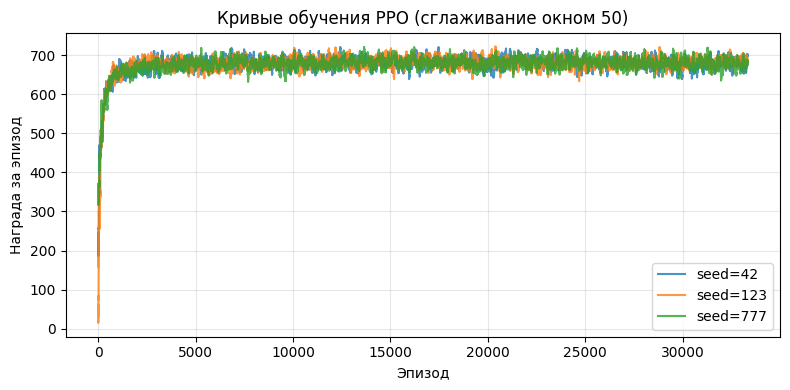

In [27]:
#Кривые обучения: награда по эпизодам, сглаживание
def smooth(x, window=50):
    #Скользящее среднее
    if len(x) < window:
        return np.array(x)
    return np.convolve(x, np.ones(window) / window, mode="valid")

plt.figure(figsize=(8, 4))
for seed in SEEDS:
    curve = trained_curves[seed]
    sm = smooth(curve, window=50)
    plt.plot(sm, label=f"seed={seed}", alpha=0.8)
plt.title("Кривые обучения PPO (сглаживание окном 50)")
plt.xlabel("Эпизод")
plt.ylabel("Награда за эпизод")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
#Видео эпизода: обученная PPO-политика при L = 1
import imageio
from IPython.display import Video, display

def record_episode(model, L=1, seed=1000, path="/content/episode.mp4"):
    env = InventoryEnv(lead_time=L, random_init=False)
    obs, _ = env.reset(seed=seed)
    frames = [env.render()]
    done = False
    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, r, term, trunc, info = env.step(int(action))
        frames.append(env.render())
        done = term or trunc
    frames += [frames[-1]] * 5
    imageio.mimsave(path, frames, fps=5)
    return path

video_path = record_episode(trained_models[SEEDS[0]], L=1, seed=1000)
display(Video(video_path, embed=True, width=960))

In [32]:
#Оценка при разных L 1,3,5,7,10: PPO (3 seed), random, эвристики
L_VALUES = [1, 3, 5, 7, 10]
N_EVAL = 20
EVAL_SEED0 = 1000

def eval_policy_at_L(policy_fn, L):
    #считаем среднюю награду и Out of stock/день
    env = InventoryEnv(lead_time=L, random_init=False)
    rewards, lost_per_day, order_per_day = [], [], []
    for s in range(EVAL_SEED0, EVAL_SEED0 + N_EVAL):
        obs, _ = env.reset(seed=s)
        done = False
        ep_r, ep_lost, ep_ord, days = 0.0, 0, 0, 0
        while not done:
            action = policy_fn(obs, env)
            obs, r, term, trunc, info = env.step(action)
            ep_r += r; ep_lost += info["lost"]; ep_ord += info["order"]; days += 1
            done = term or trunc
        rewards.append(ep_r); lost_per_day.append(ep_lost / days); order_per_day.append(ep_ord / days)
    return np.mean(rewards), np.std(rewards), np.mean(lost_per_day), np.mean(order_per_day)

def eval_model_at_L(model, L):
    #жадная политика PPO на сыром наблюдении (norm_obs=False)
    return eval_policy_at_L(lambda obs, env: int(model.predict(obs, deterministic=True)[0]), L)

results = {L: {} for L in L_VALUES}

for L in L_VALUES:
    #случайная политика
    m, s, l, o = eval_policy_at_L(lambda obs, env: env.action_space.sample(), L)
    results[L]["random"] = (m, s, l)
    # эвристика order-up-to 25
    pol25 = order_up_to_policy(25)
    m, s, l, o = eval_policy_at_L(pol25, L)
    results[L]["oul25"] = (m, s, l)
    #умная эвритика order-up-to под текущий L с Safety stock
    pol_smart, tgt = smart_order_up_to(5.0, L)
    m, s, l, o = eval_policy_at_L(pol_smart, L)
    results[L]["smart"] = (m, s, l)
    #PPO: среднее и std по seed
    rewards_seeds, lost_seeds, ord_seeds = [], [], []
    for seed in SEEDS:
        m, s, l, o = eval_model_at_L(trained_models[seed], L)
        rewards_seeds.append(m); lost_seeds.append(l); ord_seeds.append(o)
    results[L]["ppo"] = (np.mean(rewards_seeds), np.std(rewards_seeds),
                         np.mean(lost_seeds), np.mean(ord_seeds))

header = (f"{'L':>3} | {'random':>13} | {'OUL25':>12} | "
          f"{'smart OUL':>12} | {'PPO (mean±std)':>12} | {'PPO oos/day':>12}")
print(header); print("-" * len(header))
for L in L_VALUES:
    rm, rs, rl = results[L]["random"]
    om, os_, ol = results[L]["oul25"]
    sm, ss, sl = results[L]["smart"]
    pm, ps, pl, po = results[L]["ppo"]
    print(f"{L:>3} | {rm:7.1f}±{rs:4.1f} | {om:7.1f}±{os_:4.1f} | "
          f"{sm:7.1f}±{ss:4.1f} | {pm:7.1f}±{ps:5.1f} | {pl:12.2f}")

  L |        random |        OUL25 |    smart OUL | PPO (mean±std) |  PPO oos/day
---------------------------------------------------------------------------------
  1 |   406.1±427.2 |   528.0±67.6 |   694.1±62.3 |   693.9±  3.0 |         0.11
  3 |   378.7±336.3 |   628.1±59.9 |   614.0±69.4 |   580.8±  8.9 |         0.54
  5 |   382.5±134.6 |   454.3±26.1 |   485.6±72.0 |   378.1±  8.7 |         1.26
  7 |   291.6±93.3 |   265.1±34.1 |   340.7±83.9 |   283.8±  5.9 |         1.72
 10 |   142.2±98.6 |    58.9±31.0 |   105.4±73.3 |    22.9± 19.1 |         2.54


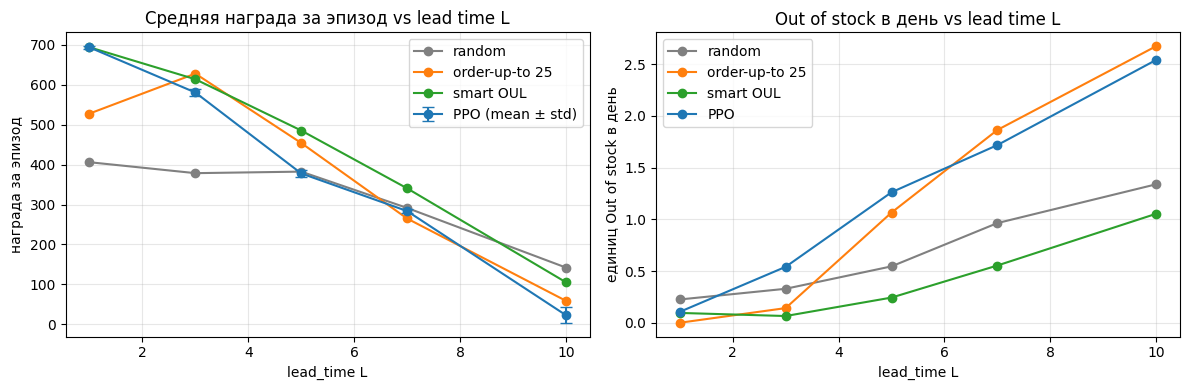

In [33]:
#Итоги: награда vs L для PPO, random и эвристик
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
#Средняя награда
ax = axes[0]
for key, label, color in [
    ("random", "random", "gray"),
    ("oul25", "order-up-to 25", "tab:orange"),
    ("smart", "smart OUL", "tab:green"),
    ("ppo", "PPO (mean ± std)", "tab:blue")]:
    means = [results[L][key][0] for L in L_VALUES]
    if key == "ppo":
        stds = [results[L][key][1] for L in L_VALUES]
        ax.errorbar(L_VALUES, means, yerr=stds, marker="o", capsize=4, label=label, color=color)
    else:
        ax.plot(L_VALUES, means, marker="o", label=label, color=color)
ax.set_title("Средняя награда за эпизод vs lead time L")
ax.set_xlabel("lead_time L")
ax.set_ylabel("награда за эпизод")
ax.grid(alpha=0.3); ax.legend()

#Out of stock/день
ax = axes[1]
for key, label, color in [
    ("random", "random", "gray"),
    ("oul25", "order-up-to 25", "tab:orange"),
    ("smart", "smart OUL", "tab:green"),
    ("ppo", "PPO", "tab:blue")]:
    lost = [results[L][key][2] for L in L_VALUES]
    ax.plot(L_VALUES, lost, marker="o", label=label, color=color)
ax.set_title("Out of stock в день vs lead time L")
ax.set_xlabel("lead_time L")
ax.set_ylabel("единиц Out of stock в день")
ax.grid(alpha=0.3); ax.legend()

plt.tight_layout()
plt.show()

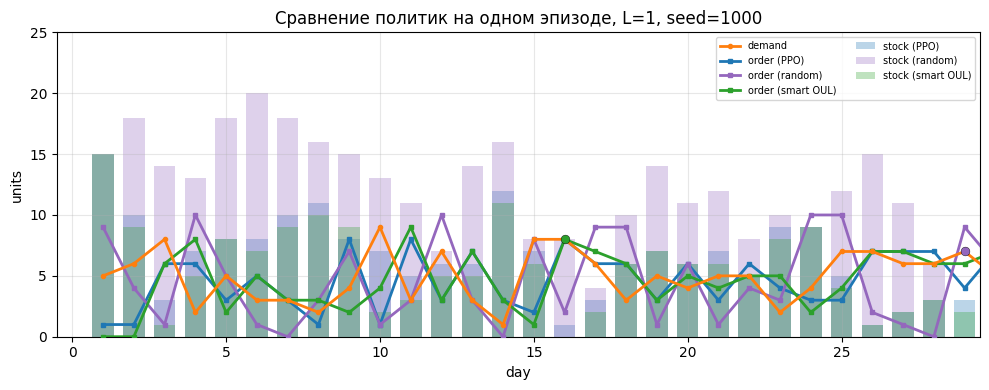

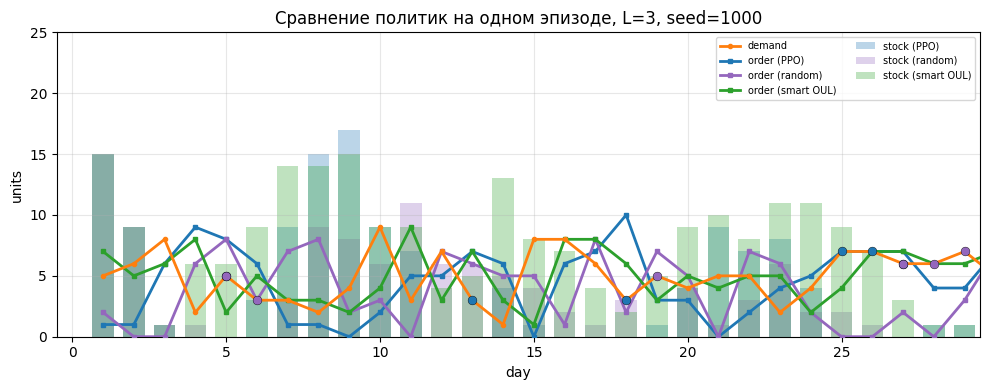

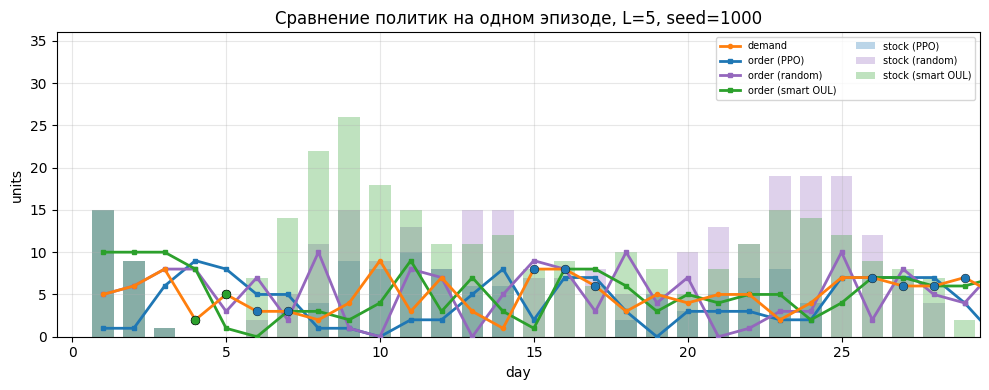

In [38]:
#Сравнение политик на одном эпизоде (одинаковый спрос)
import matplotlib.pyplot as plt

def collect_episode(policy_fn, L, seed):
    env = InventoryEnv(lead_time=L, random_init=False)
    obs, _ = env.reset(seed=seed)
    done = False
    while not done:
        action = policy_fn(obs, env)
        obs, r, term, trunc, info = env.step(int(action))
        done = term or trunc
        env.render()
    return env.history

def plot_policies_compare(L, seed=1000):
    ppo_pol = lambda obs, env: int(trained_models[SEEDS[0]].predict(obs, deterministic=True)[0])
    pol_smart, _ = smart_order_up_to(5.0, L)

    histories = {
        "PPO":            collect_episode(ppo_pol, L, seed),
        "random":         collect_episode(random_policy, L, seed),
        "smart OUL":      collect_episode(pol_smart, L, seed)}

    days    = [h["day"] for h in histories["PPO"]]
    demands = [h["demand"] for h in histories["PPO"]]

    # Цвета: у каждой политики один цвет для запаса и заказов
    colors = {
        "PPO":       "tab:blue",
        "random":    "tab:purple",
        "smart OUL": "tab:green"}

    fig, ax = plt.subplots(figsize=(10, 4), dpi=100)

    #Demand: оранжевая линия, общая для всех
    ax.plot(days, demands, color="tab:orange", marker="o", markersize=3,
            linewidth=2, label="demand", zorder=4)

    #Запас:полупрозрачные столбики в цвете политики
    for name, hist in histories.items():
        stocks = [h["stock"] for h in hist]
        ax.bar(days, stocks, width=0.7, color=colors[name], alpha=0.3,
               linewidth=0, label=f"stock ({name})", zorder=1)

    #Заказы: линии в цвете политики
    for name, hist in histories.items():
        orders = [h["order"] for h in hist]
        ax.plot(days, orders, color=colors[name], marker="s", markersize=3,
                linewidth=2, label=f"order ({name})", zorder=3)

    # Out of stock — точки на линии спроса, цвет политики
    for name, hist in histories.items():
        losts = [h["lost"] for h in hist]
        for d, l, dm in zip(days, losts, demands):
            if l > 0:
                ax.scatter(d, dm, color=colors[name], s=40, zorder=5,
                           edgecolors="black", linewidths=0.3)

    ax.set_xlim(-0.5, len(days) - 0.5)
    ax.set_ylim(0, max(max(h["stock"] for h in histories["smart OUL"]),
                       max(demands),
                       max(h["order"] for h in histories["smart OUL"])) + 10)
    ax.set_xlabel("day")
    ax.set_ylabel("units")
    ax.set_title(f"Сравнение политик на одном эпизоде, L={L}, seed={seed}")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=7, ncol=2)
    plt.tight_layout()
    plt.show()
    plt.close("all")


plot_policies_compare(L=1, seed=1000)
plot_policies_compare(L=3, seed=1000)
plot_policies_compare(L=5, seed=1000)

##**Выводы и анализ**

**Гипотеза подтвердилась частично**: качество политики PPO падает с ростом *L*, при этом падение носит нелинейный характер. Oно умеренное при переходе от *L=1* к *L=3* и становится резким при *L≥5*, но порог как таковой не выделяется. Исходная гипотеза о наличии чёткого порога L не подтвердилась: деградация нарастает плавно, без резкого скачка в одной точке.

При *L=1* (условие обучения) PPO достигает уровня лучшего ориентира (*smart OUL*) и гораздо лучше случайного агента и простой эвритиски, что подтверждает работоспособность решения. Обучение даёт измеримое улучшение относительно random и наивной эвристики OUL25. При *L=3* PPO ещё превосходит наивную эвристику OUL25, но уже уступает smart OUL; начиная с *L=5* PPO проигрывает всем ориентирам, включая random и OUL25, а при *L=10* опускается ниже случайной политики. Кривые обучения всех seed'ов после ~15-20 тыс. эпизодов выходят на плато с заметными флуктуациями, что указывает на стабилизацию процесса обучения. Поскольку итоговое качество при *L=1* у всех seed'ов близко, можно предположить, что причина плохого обобщения не в нестабильности обучения, а в самой политике, обученной под конкретную динамику L=1. Политика, обученная на *lead_time=1*, не переносится на lead_time=3 (падение 16%). Без рандомизации параметров среды или мета-обучения обобщение на сдвиг динамики не гарантируется.

Сравнение с ориентирами выявляет природу деградации. Три бейзлайна покрывают разные уровни: random - нижняя граница, OUL25 - наивная стратегия, не знающая *L*, smart OUL - адаптивная, знающая *L* и пересчитывающая target с safety stock. Политика PPO, обученная при L=1, при больших L демонстрирует качество ниже случайной политики, что свидетельствует о  том, что выученная при L=1 политика не обобщается на большие L в рамках данной постановки. Это может быть связано с тем, что агент не может адаптировать стратегию заказа к возросшему времени выполнения, что приводит к неоптимальному распределению запасов во времени. При этом smart OUL при больших *L* остаётся единственным ориентиром в положительной зоне. Это показывает, что задача в принципе решаема, но только если политика знает *L* и планирует с учётом задержки.

Причина деградации видна по Out of stock. oos/day у PPO растёт с *L* в несколько раз, и при больших задержках он уходит в дефицит сильнее, чем smart OUL и random. Награда падает за счет того, что агент перестаёт покрывать спрос. Использование двух метрик (награда и Out of stock) даёт согласованную картину и позволяет отделить «политика стала хуже» от «задача стала сложнее». Smart OUL показывает, что при знании *L* задача остаётся решаемой, а PPO иллюстрирует, что без обобщения по *L*  качество политики падает ниже уровня случайной.

**Рекомендации по оптимизации:**

 (1) Добавить текущий *L* в вектор наблюдения *(L / max_lead)*. Сейчас агент не знает задержку и не может адаптировать горизонт планирования. Это даст агенту информацию, необходимую для адаптации горизонта планирования, однако простое добавление признака не гарантирует, что политика научится его использовать. Потребуется долполнительная проверка

 (2) Модифицировать функцию награды: добавить штраф за ожидаемый дефицит. Для этого нужно смоделировать ожидаемый спрос на время *L+1* и добавить штраф за *max(0, mu·(L+1) - (stock + sum(pipeline[:L+1])))*. Ввести понятие Potential OOS. Это должно стимулировать агента быть более дальновидным при больших *L*, но с оговоркой на потенциальный reward hacking.

 (3) Использовать Curriculum Learning: начать обучение с L=1, затем постепенно увеличивать L до 10. Это позволит агенту сначала выучить базовую стратегию, а затем научиться ее адаптировать к большим задержкам, в отличие от простой рандомизации, которая может создать слишком сложную задачу с самого начала.


